# 문제 5 사후 실험
기존 개발 600장만으로 후보를 비교한다. 확인 150장과 test 채점 결과는 모델 선택에 사용하지 않는다. 공식 원 제출 점수는 사용자 제공 Macro-F1 0.9678, 정확도 242/250이다.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS']='2'
os.environ['OMP_NUM_THREADS']='2'
import json,time,warnings
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image,ImageDraw
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.preprocessing import StandardScaler,Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC,SVC
from sklearn.metrics import f1_score,confusion_matrix,classification_report
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from feature_helper import extract_features
thread_limit=threadpool_limits(limits=2)
train=pd.read_csv('data/train.csv');test=pd.read_csv('data/test.csv');sample=pd.read_csv('data/sample_submission.csv')
X=extract_features(train.image_path.tolist(),cache_path='train_features.npz')
Xt=extract_features(test.image_path.tolist(),cache_path='test_features.npz')
y=train.label.to_numpy();labels=[0,1,2,3,4]
dev,hold=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=42)
folds=list(StratifiedKFold(3,shuffle=True,random_state=42).split(X[dev],y[dev]))
assert len(dev)==600 and len(hold)==150 and not set(dev)&set(hold)
def macro(a,b):return float(f1_score(a,b,labels=labels,average='macro',zero_division=0))
candidates=[('LR_C1',LogisticRegression(C=1,max_iter=2000),0,1),
 ('LinearSVC_C0.1',LinearSVC(C=.1,dual='auto',max_iter=5000,random_state=42),1,.1),
 ('RBF_C1',SVC(C=1,gamma='scale',probability=False),2,1),
 ('LR_C10',LogisticRegression(C=10,max_iter=2000),0,10),
 ('LinearSVC_C1',LinearSVC(C=1,dual='auto',max_iter=5000,random_state=42),1,1),
 ('RBF_C10',SVC(C=10,gamma='scale',probability=False),2,10)]
def preprocessing():return make_pipeline(StandardScaler(),Normalizer())
def evaluate(model,features):
    t=time.perf_counter();pred=np.full(len(dev),-1,int);fs=[];fc=[];ws_all=[]
    for tr,va in folds:
        fit=clone(model)
        with warnings.catch_warnings(record=True) as ws:
            warnings.simplefilter('always');fit.fit(features[dev[tr]],y[dev[tr]])
        if any(issubclass(w.category,ConvergenceWarning) for w in ws):
            fit.set_params(**{list(fit.named_steps)[-1]+'__max_iter':fit.steps[-1][1].max_iter*2})
            with warnings.catch_warnings(record=True) as ws:
                warnings.simplefilter('always');fit.fit(features[dev[tr]],y[dev[tr]])
        ws_all.extend(str(w.message) for w in ws)
        assert not any(issubclass(w.category,ConvergenceWarning) for w in ws),'Unresolved convergence'
        pred[va]=fit.predict(features[dev[va]])
        fs.append(macro(y[dev[va]],pred[va]))
        fc.append(f1_score(y[dev[va]],pred[va],labels=labels,average=None,zero_division=0).tolist())
    return dict(score=macro(y[dev],pred),fold_scores=fs,fold_class_f1=fc,
      class_f1=f1_score(y[dev],pred,labels=labels,average=None,zero_division=0).tolist(),
      confusion=confusion_matrix(y[dev],pred,labels=labels).tolist(),
      seconds=time.perf_counter()-t,warnings=ws_all),pred


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-01 18:45:49.877526528 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


Using cached image features.
Using cached image features.


In [2]:
results={};predictions={}
for name,est,rank,c in candidates:
    results[name],predictions[name]=evaluate(make_pipeline(preprocessing(),clone(est)),X)
    results[name].update(rank=rank,C=c)
    print(name,results[name]['score'],results[name]['fold_scores'])
original=json.loads(Path('experiment_results.json').read_text())
assert np.isclose(results['LR_C1']['score'],original['pooled_oof_macro_f1'],atol=1e-12,rtol=0)
best=max(v['score'] for v in results.values())
selected=min((k for k,v in results.items() if best-v['score']<=.005),key=lambda k:(results[k]['rank'],results[k]['C']))
weak=int(np.argmin(results[selected]['class_f1']))
print('Selected:',selected,'weak class fixed before extra-feature evaluation:',weak)
display(pd.DataFrame({k:{'pooled_macro_f1':v['score'],'seconds':v['seconds']} for k,v in results.items()}).T)
Path('posthoc_results.json').write_text(json.dumps(dict(candidates=results,selected=selected,weak_class=weak),indent=2))
np.savez_compressed('posthoc_oof.npz',dev=dev,hold=hold,**predictions)


LR_C1 0.9465995744400256 [0.9295952375297851, 0.9399233053241491, 0.9699767746026259]
LinearSVC_C0.1 0.944735781164024 [0.9343203480817349, 0.9295749048728362, 0.9699767746026259]


RBF_C1 0.9549636746784944 [0.9497349917186286, 0.9451673221103085, 0.9699867108105247]
LR_C10 0.9581519088767063 [0.9495868178795007, 0.9497968373928032, 0.9748647595910125]


LinearSVC_C1 0.9580720074758823 [0.9495868178795007, 0.9598670465337132, 0.964573421873642]


RBF_C10 0.9566368229391704 [0.9547869151038852, 0.9451673221103085, 0.9699867108105247]
Selected: LR_C10 weak class fixed before extra-feature evaluation: 4


,pooled_macro_f1,seconds
LR_C1,0.946600,0.130178
LinearSVC_C0.1,0.944736,0.131417
RBF_C1,0.954964,0.529978
LR_C10,0.958152,0.165622
LinearSVC_C1,0.958072,0.161797
RBF_C10,0.956637,0.520826


,0,1,2,3,4
0,118,0,0,1,1
1,0,115,1,0,4
2,2,0,118,0,0
3,2,0,2,115,1
4,1,4,1,5,109


              precision    recall  f1-score   support

           0       0.96      0.98      0.97       120
           1       0.97      0.96      0.96       120
           2       0.97      0.98      0.98       120
           3       0.95      0.96      0.95       120
           4       0.95      0.91      0.93       120

    accuracy                           0.96       600
   macro avg       0.96      0.96      0.96       600
weighted avg       0.96      0.96      0.96       600

Confusion pairs: [(8, 1, 4), (6, 3, 4), (3, 0, 3), (2, 2, 3), (2, 0, 4), (2, 0, 2), (1, 2, 4), (1, 1, 2), (0, 1, 3), (0, 0, 1)]


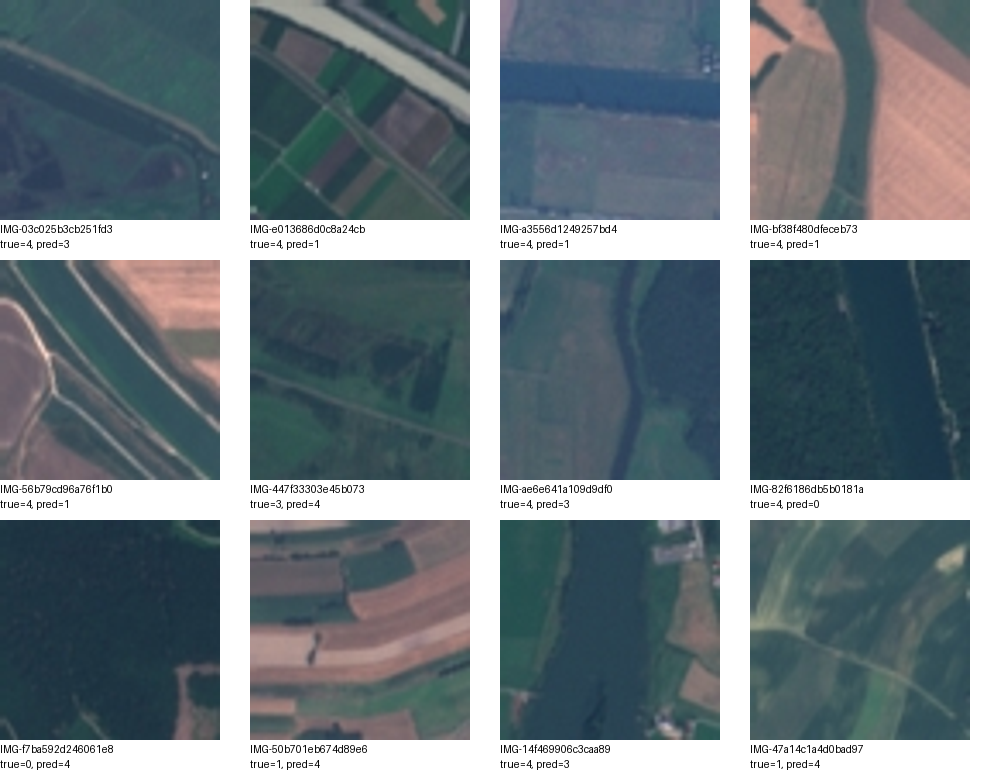

In [3]:
pred=predictions[selected];cm=np.array(results[selected]['confusion'])
display(pd.DataFrame(cm,index=labels,columns=labels))
print(classification_report(y[dev],pred,labels=labels,zero_division=0))
pairs=sorted([(int(cm[a,b]+cm[b,a]),a,b) for a in labels for b in labels if a<b],reverse=True)
print('Confusion pairs:',pairs)
errors=np.flatnonzero(pred!=y[dev])
priority=sorted(errors,key=lambda i:(not (y[dev[i]]==weak or pred[i]==weak),int(i)))[:12]
sheet=Image.new('RGB',(1000,780),'white');draw=ImageDraw.Draw(sheet)
for k,j in enumerate(priority):
    row=train.iloc[dev[j]];xx=(k%4)*250;yy=(k//4)*260
    with Image.open(row.image_path) as im:sheet.paste(im.resize((220,220)),(xx,yy))
    draw.text((xx,yy+223),f"{row.image_id}",fill='black')
    draw.text((xx,yy+238),f"true={int(row.label)}, pred={int(pred[j])}",fill='black')
sheet.save('posthoc_errors.png');display(sheet)
error_table=train.iloc[dev[errors]][['image_id','image_path','label']].copy()
error_table['oof_prediction']=pred[errors]
error_table.to_csv('posthoc_errors.csv',index=False)


## 색상·질감 12개 추가 실험
오류 예시에서 좁은 수로와 주변 토지가 함께 보인다. 전역 색상·질감 통계의 개선 여부는 미확인이다. 추가 평가 전 하천(4)을 약한 클래스로 고정했다. 기존 계획의 네 조건으로만 채택한다.

In [4]:
r=json.loads(Path('posthoc_results.json').read_text())
selected=r['selected'];weak=r['weak_class'];base=r['candidates'][selected]
est=next(clone(e) for n,e,_,_ in candidates if n==selected)
def image_stats(paths):
    values=[]
    for path in paths:
        with Image.open(path) as im:
            im=im.convert('RGB');a=np.asarray(im,dtype=float)/255
            sv=np.asarray(im.convert('HSV'),dtype=float)[:,:,1:]/255
        gray=a.mean(axis=2)
        values.append(np.r_[a.mean(axis=(0,1)),a.std(axis=(0,1)),
            sv.mean(axis=(0,1)),sv.std(axis=(0,1)),
            np.abs(np.diff(gray,axis=1)).mean(),np.abs(np.diff(gray,axis=0)).mean()])
    out=np.asarray(values)
    assert out.shape==(len(paths),12) and np.isfinite(out).all()
    return out
extra_train=image_stats(train.image_path.tolist())
features=np.hstack([X,extra_train])
blocks=ColumnTransformer([('encoder',preprocessing(),list(range(1280))),
 ('extra',preprocessing(),list(range(1280,1292)))],transformer_weights={'encoder':1.,'extra':.25})
aug_model=make_pipeline(blocks,clone(est))
aug,pred_extra=evaluate(aug_model,features)
delta=aug['score']-base['score']
class_delta=np.array(aug['class_f1'])-base['class_f1']
fold_delta=np.array(aug['fold_scores'])-base['fold_scores']
criteria={'macro_gain_at_least_0.005':bool(delta>=.005),
 'positive_in_at_least_2_folds':bool((fold_delta>0).sum()>=2),
 'weak_class_improves':bool(class_delta[weak]>0),
 'no_class_loses_more_than_0.03':bool(class_delta.min()>=-.03)}
adopt=all(criteria.values())
print('Extra features:',aug['score'],'delta:',delta,'fold delta:',fold_delta)
print('Class delta:',class_delta,'criteria:',criteria,'adopt:',adopt)
display(pd.DataFrame(aug['confusion'],index=labels,columns=labels))
r.update(extra_features=aug,extra_delta=float(delta),extra_criteria=criteria,extra_adopted=adopt,
 visual_observation='Several river errors contain narrow waterways surrounded by fields/grass; global color summaries may emphasize surroundings. Visual hypothesis only; labels not changed.')
np.savez_compressed('posthoc_extra_oof.npz',dev=dev,predictions=pred_extra)
# The selection is complete. No use of the previous holdout score or test truth.
if adopt:
    final=aug_model;fit_X=features
    fit_Xt=np.hstack([Xt,image_stats(test.image_path.tolist())])
else:
    final=make_pipeline(preprocessing(),clone(est));fit_X=X;fit_Xt=Xt
final.fit(fit_X,y)
pred=final.predict(fit_Xt).astype(int)
sub=sample[['image_id']].copy();sub['label']=sub.image_id.map(pd.Series(pred,index=test.image_id)).astype(int)
assert list(sub.columns)==['image_id','label'] and len(sub)==250 and sub.image_id.is_unique
assert sub.image_id.equals(sample.image_id) and sub.label.isin(labels).all() and not sub.isna().any().any()
# Only create a new candidate when development performance improves over the original baseline.
final_score=aug['score'] if adopt else base['score']
assert final_score>r['candidates']['LR_C1']['score']
sub.to_csv('submission_codex_posthoc.csv',index=False)
back=pd.read_csv('submission_codex_posthoc.csv');pd.testing.assert_frame_equal(sub,back)
old=pd.read_csv('submission_codex.csv').set_index('image_id').loc[sub.image_id,'label'].to_numpy()
changed=sub.loc[old!=sub.label.to_numpy()].copy();changed['original_label']=old[old!=sub.label.to_numpy()]
changed.to_csv('posthoc_changed_predictions.csv',index=False)
r.update(final_model=selected,final_uses_extra=adopt,final_oof_score=final_score,
 changed_test_predictions=len(changed),test_prediction_counts={str(k):int(v) for k,v in sub.label.value_counts().sort_index().items()})
Path('posthoc_results.json').write_text(json.dumps(r,indent=2,ensure_ascii=False))
print('Saved posthoc candidate. Changed test predictions:',len(changed))
print('Test performance is unknown. The original submission is preserved.')


Extra features: 0.9581560302514177 delta: 4.121374711396619e-06 fold delta: [ 0.01006648 -0.01007826  0.        ]
Class delta: [ 0.          0.0083682  -0.0040132  -0.00829876  0.00396436] criteria: {'macro_gain_at_least_0.005': False, 'positive_in_at_least_2_folds': False, 'weak_class_improves': True, 'no_class_loses_more_than_0.03': True} adopt: False


,0,1,2,3,4
0,118,0,0,1,1
1,0,116,1,0,3
2,2,0,118,0,0
3,2,0,3,114,1
4,1,3,1,6,109


Saved posthoc candidate. Changed test predictions: 2
Test performance is unknown. The original submission is preserved.
